|<h2>Book:</h2>|<h1><a href="https://open.substack.com/pub/mikexcohen/p/llm-breakdown-16-tokenization-words" target="_blank">50 ML projects to understand LLMs</a></h1>|
|-|:-:|
|<h2>Project:</h2>|<h1><b>[22] Evaluating models with HellaSwag</b></h1>|
|<h2>Author:<h2>|<h1>Mike X Cohen, <a href="https://sincxpress.com" target="_blank">sincxpress.com</a></h1>|

<br>

<i>Using the code without reading the book may lead to confusion or errors.</i>

In [24]:
import numpy as np
import matplotlib.pyplot as plt

from tqdm import tqdm
from datasets import load_dataset

from statsmodels.stats.contingency_tables import mcnemar

# pytorch-related libraries
import torch
import torch.nn as nn
import torch.nn.functional as F

# libraries to import models
from transformers import AutoModelForCausalLM, AutoTokenizer
from transformers import RobertaTokenizer, RobertaForMaskedLM

In [25]:
### matplotlib adjustments (commented lines are for dark mode)

# svg plots (higher-res)
import matplotlib_inline.backend_inline
matplotlib_inline.backend_inline.set_matplotlib_formats('svg')

plt.rcParams.update({
    # 'figure.facecolor': '#282a2c',
    # 'figure.edgecolor': '#282a2c',
    # 'axes.facecolor':   '#282a2c',
    # 'axes.edgecolor':   '#DDE2F4',
    # 'axes.labelcolor':  '#DDE2F4',
    # 'xtick.color':      '#DDE2F4',
    # 'ytick.color':      '#DDE2F4',
    # 'text.color':       '#DDE2F4',
    'axes.spines.right': False,
    'axes.spines.top':   False,
    'axes.titleweight': 'bold',
    'axes.labelweight': 'bold',
    'savefig.dpi':50,
})

# **Part 1: Import and compare GPT2 and RoBERTa**

In [26]:
# use the GPU if available
device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')

# import the tokenizer and models
tokenizerG = AutoTokenizer.from_pretrained('gpt2')
gpt2_s = AutoModelForCausalLM.from_pretrained('gpt2').to(device)
gpt2_l = AutoModelForCausalLM.from_pretrained('gpt2-large').to(device)

# switch to evaluation (inference) mode
gpt2_s.eval()
gpt2_l.eval()

Loading weights:   0%|          | 0/148 [00:00<?, ?it/s]

Loading weights:   0%|          | 0/436 [00:00<?, ?it/s]

GPT2LMHeadModel(
  (transformer): GPT2Model(
    (wte): Embedding(50257, 1280)
    (wpe): Embedding(1024, 1280)
    (drop): Dropout(p=0.1, inplace=False)
    (h): ModuleList(
      (0-35): 36 x GPT2Block(
        (ln_1): LayerNorm((1280,), eps=1e-05, elementwise_affine=True)
        (attn): GPT2Attention(
          (c_attn): Conv1D(nf=3840, nx=1280)
          (c_proj): Conv1D(nf=1280, nx=1280)
          (attn_dropout): Dropout(p=0.1, inplace=False)
          (resid_dropout): Dropout(p=0.1, inplace=False)
        )
        (ln_2): LayerNorm((1280,), eps=1e-05, elementwise_affine=True)
        (mlp): GPT2MLP(
          (c_fc): Conv1D(nf=5120, nx=1280)
          (c_proj): Conv1D(nf=1280, nx=5120)
          (act): NewGELUActivation()
          (dropout): Dropout(p=0.1, inplace=False)
        )
      )
    )
    (ln_f): LayerNorm((1280,), eps=1e-05, elementwise_affine=True)
  )
  (lm_head): Linear(in_features=1280, out_features=50257, bias=False)
)

Loading weights:   0%|          | 0/148 [00:00<?, ?it/s]

Loading weights:   0%|          | 0/436 [00:00<?, ?it/s]

GPT2LMHeadModel(
  (transformer): GPT2Model(
    (wte): Embedding(50257, 1280)
    (wpe): Embedding(1024, 1280)
    (drop): Dropout(p=0.1, inplace=False)
    (h): ModuleList(
      (0-35): 36 x GPT2Block(
        (ln_1): LayerNorm((1280,), eps=1e-05, elementwise_affine=True)
        (attn): GPT2Attention(
          (c_attn): Conv1D(nf=3840, nx=1280)
          (c_proj): Conv1D(nf=1280, nx=1280)
          (attn_dropout): Dropout(p=0.1, inplace=False)
          (resid_dropout): Dropout(p=0.1, inplace=False)
        )
        (ln_2): LayerNorm((1280,), eps=1e-05, elementwise_affine=True)
        (mlp): GPT2MLP(
          (c_fc): Conv1D(nf=5120, nx=1280)
          (c_proj): Conv1D(nf=1280, nx=5120)
          (act): NewGELUActivation()
          (dropout): Dropout(p=0.1, inplace=False)
        )
      )
    )
    (ln_f): LayerNorm((1280,), eps=1e-05, elementwise_affine=True)
  )
  (lm_head): Linear(in_features=1280, out_features=50257, bias=False)
)

In [27]:
# import roberta model and tokenizer
tokenizerR = RobertaTokenizer.from_pretrained('roberta-base')
roberta_s = RobertaForMaskedLM.from_pretrained('roberta-base').to(device)
roberta_l = RobertaForMaskedLM.from_pretrained('roberta-large').to(device)

roberta_s.eval()
roberta_l.eval()

Loading weights:   0%|          | 0/202 [00:00<?, ?it/s]

Loading weights:   0%|          | 0/394 [00:00<?, ?it/s]

RobertaForMaskedLM(
  (roberta): RobertaModel(
    (embeddings): RobertaEmbeddings(
      (word_embeddings): Embedding(50265, 1024, padding_idx=1)
      (token_type_embeddings): Embedding(1, 1024)
      (LayerNorm): LayerNorm((1024,), eps=1e-05, elementwise_affine=True)
      (dropout): Dropout(p=0.1, inplace=False)
      (position_embeddings): Embedding(514, 1024, padding_idx=1)
    )
    (encoder): RobertaEncoder(
      (layer): ModuleList(
        (0-23): 24 x RobertaLayer(
          (attention): RobertaAttention(
            (self): RobertaSelfAttention(
              (query): Linear(in_features=1024, out_features=1024, bias=True)
              (key): Linear(in_features=1024, out_features=1024, bias=True)
              (value): Linear(in_features=1024, out_features=1024, bias=True)
              (dropout): Dropout(p=0.1, inplace=False)
            )
            (output): RobertaSelfOutput(
              (dense): Linear(in_features=1024, out_features=1024, bias=True)
              (

Loading weights:   0%|          | 0/202 [00:00<?, ?it/s]

Loading weights:   0%|          | 0/394 [00:00<?, ?it/s]

RobertaForMaskedLM(
  (roberta): RobertaModel(
    (embeddings): RobertaEmbeddings(
      (word_embeddings): Embedding(50265, 1024, padding_idx=1)
      (token_type_embeddings): Embedding(1, 1024)
      (LayerNorm): LayerNorm((1024,), eps=1e-05, elementwise_affine=True)
      (dropout): Dropout(p=0.1, inplace=False)
      (position_embeddings): Embedding(514, 1024, padding_idx=1)
    )
    (encoder): RobertaEncoder(
      (layer): ModuleList(
        (0-23): 24 x RobertaLayer(
          (attention): RobertaAttention(
            (self): RobertaSelfAttention(
              (query): Linear(in_features=1024, out_features=1024, bias=True)
              (key): Linear(in_features=1024, out_features=1024, bias=True)
              (value): Linear(in_features=1024, out_features=1024, bias=True)
              (dropout): Dropout(p=0.1, inplace=False)
            )
            (output): RobertaSelfOutput(
              (dense): Linear(in_features=1024, out_features=1024, bias=True)
              (

In [28]:
# FYI, useful model information
roberta_s.config

RobertaConfig {
  "add_cross_attention": false,
  "architectures": [
    "RobertaForMaskedLM"
  ],
  "attention_probs_dropout_prob": 0.1,
  "bos_token_id": 0,
  "classifier_dropout": null,
  "dtype": "float32",
  "eos_token_id": 2,
  "hidden_act": "gelu",
  "hidden_dropout_prob": 0.1,
  "hidden_size": 768,
  "initializer_range": 0.02,
  "intermediate_size": 3072,
  "is_decoder": false,
  "layer_norm_eps": 1e-05,
  "max_position_embeddings": 514,
  "model_type": "roberta",
  "num_attention_heads": 12,
  "num_hidden_layers": 12,
  "pad_token_id": 1,
  "tie_word_embeddings": true,
  "transformers_version": "5.20.1",
  "type_vocab_size": 1,
  "use_cache": true,
  "vocab_size": 50265
}

RobertaConfig {
  "add_cross_attention": false,
  "architectures": [
    "RobertaForMaskedLM"
  ],
  "attention_probs_dropout_prob": 0.1,
  "bos_token_id": 0,
  "classifier_dropout": null,
  "dtype": "float32",
  "eos_token_id": 2,
  "hidden_act": "gelu",
  "hidden_dropout_prob": 0.1,
  "hidden_size": 768,
  "initializer_range": 0.02,
  "intermediate_size": 3072,
  "is_decoder": false,
  "layer_norm_eps": 1e-05,
  "max_position_embeddings": 514,
  "model_type": "roberta",
  "num_attention_heads": 12,
  "num_hidden_layers": 12,
  "pad_token_id": 1,
  "tie_word_embeddings": true,
  "transformers_version": "5.20.1",
  "type_vocab_size": 1,
  "use_cache": true,
  "vocab_size": 50265
}

In [29]:
# table of model sizes

print(' Model | Tokens | Emb.dim | Xfmr | Parameters')
print('-------+--------+---------+------+-------------')

# GPT2-small
print(f'GPT2-S | {tokenizerG.vocab_size:,} |   {gpt2_s.config.n_embd:4}  |  {gpt2_s.config.n_layer}  | {gpt2_s.num_parameters():,}')

# GPT2-large
print(f'GPT2-L | {tokenizerG.vocab_size:,} |   {gpt2_l.config.n_embd:4}  |  {gpt2_l.config.n_layer}  | {gpt2_l.num_parameters():,}')

# roberta-small
print(f'RoBA-S | {tokenizerR.vocab_size:,} |   {roberta_s.config.hidden_size:4}  |  {roberta_s.config.num_hidden_layers}  | {roberta_s.num_parameters():,}')

# roberta-large
print(f'RoBA-L | {tokenizerR.vocab_size:,} |   {roberta_l.config.hidden_size:4}  |  {roberta_l.config.num_hidden_layers}  | {roberta_l.num_parameters():,}')


 Model | Tokens | Emb.dim | Xfmr | Parameters
-------+--------+---------+------+-------------
GPT2-S | 50,257 |    768  |  12  | 124,439,808
GPT2-L | 50,257 |   1280  |  36  | 774,030,080
RoBA-S | 50,265 |    768  |  12  | 124,697,433
RoBA-L | 50,265 |   1024  |  24  | 355,412,057
 Model | Tokens | Emb.dim | Xfmr | Parameters
-------+--------+---------+------+-------------
GPT2-S | 50,257 |    768  |  12  | 124,439,808
GPT2-L | 50,257 |   1280  |  36  | 774,030,080
RoBA-S | 50,265 |    768  |  12  | 124,697,433
RoBA-L | 50,265 |   1024  |  24  | 355,412,057


# **Part 2: Import and explore HellaSwag**

In [30]:
# import the HellaSwag validation set
dataset = load_dataset('allenai/hellaswag',split='validation')
dataset

Dataset({
    features: ['ind', 'activity_label', 'ctx_a', 'ctx_b', 'ctx', 'endings', 'source_id', 'split', 'split_type', 'label'],
    num_rows: 10042
})

Dataset({
    features: ['ind', 'activity_label', 'ctx_a', 'ctx_b', 'ctx', 'endings', 'source_id', 'split', 'split_type', 'label'],
    num_rows: 10042
})

In [31]:
# an example
dataset[1]

{'ind': 92,
 'activity_label': 'Clean and jerk',
 'ctx_a': 'A lady walks to a barbell. She bends down and grabs the pole.',
 'ctx_b': 'the lady',
 'ctx': 'A lady walks to a barbell. She bends down and grabs the pole. the lady',
 'endings': ['swings and lands in her arms.',
  'pulls the barbell forward.',
  'pulls a rope attached to the barbell.',
  'stands and lifts the weight over her head.'],
 'source_id': 'activitynet~v_-lJS58hyo1c',
 'split': 'val',
 'split_type': 'zeroshot',
 'label': '3'}

{'ind': 92,
 'activity_label': 'Clean and jerk',
 'ctx_a': 'A lady walks to a barbell. She bends down and grabs the pole.',
 'ctx_b': 'the lady',
 'ctx': 'A lady walks to a barbell. She bends down and grabs the pole. the lady',
 'endings': ['swings and lands in her arms.',
  'pulls the barbell forward.',
  'pulls a rope attached to the barbell.',
  'stands and lifts the weight over her head.'],
 'source_id': 'activitynet~v_-lJS58hyo1c',
 'split': 'val',
 'split_type': 'zeroshot',
 'label': '3'}

# **Part 3: Visualize the evaluation process**

In [32]:
# pick a random example
exampleNum = 224
target = int(dataset[exampleNum]['label']) # the target answer

# context tokens and length
context = dataset[exampleNum]['ctx']
context_len = len( tokenizerG.encode(context) )

# prompts and their lengths
promptC = f"{context} {dataset[exampleNum]['endings'][target]}"
promptC_tox = tokenizerG.encode(promptC,return_tensors='pt')
promptC_len = len( promptC_tox[0] )

promptI = f"{context} {dataset[exampleNum]['endings'][3-target]}"
promptI_tox = tokenizerG.encode(promptI,return_tensors='pt')
promptI_len = len( promptI_tox[0] )

# show the prompts
print(f'Context:\n   "{context}"\n')
print(f'Correct ending:\n   "{promptC}"\n')
print(f'Incorrect ending:\n   "{promptI}"')

Context:
   "People watch a parade where people walk on front a marching band holding a banner and waving the viewers. a man"

Correct ending:
   "People watch a parade where people walk on front a marching band holding a banner and waving the viewers. a man cross the street holding a small flag and extend his hand."

Incorrect ending:
   "People watch a parade where people walk on front a marching band holding a banner and waving the viewers. a man wearing an orange jacket falls over from the fall, they help him up."
Context:
   "People watch a parade where people walk on front a marching band holding a banner and waving the viewers. a man"

Correct ending:
   "People watch a parade where people walk on front a marching band holding a banner and waving the viewers. a man cross the street holding a small flag and extend his hand."

Incorrect ending:
   "People watch a parade where people walk on front a marching band holding a banner and waving the viewers. a man wearing an orange jack

In [33]:
# forward pass through the model
with torch.no_grad():
  logitsC = gpt2_s(promptC_tox.to(device)).logits
  logitsI = gpt2_s(promptI_tox.to(device)).logits

# log softmax (more numerically stable than prob values for later calculations)
log_sm_C = F.log_softmax(logitsC,dim=-1)
log_sm_I = F.log_softmax(logitsI,dim=-1)


# get the sequence of sm logits for the correct prompt
lsmSeqC = np.zeros(promptC_len-1)
for i in range(0,promptC_len-1):
  lsmSeqC[i] = log_sm_C[0,i,promptC_tox[0][i+1]]

# repeat for the incorrect prompt
lsmSeqI = np.zeros(promptI_len-1)
for i in range(0,promptI_len-1):
  lsmSeqI[i] = log_sm_I[0,i,promptI_tox[0][i+1]]

# probabilities of prompts (sum of logs equals product of probabilities)
probC = lsmSeqC[context_len-1:].mean()
probI = lsmSeqI[context_len-1:].mean()

print(f'    Target ending log-prob: {probC:.3f}')
print(f'Non-target ending log-prob: {probI:.3f}')

    Target ending log-prob: -3.631
Non-target ending log-prob: -3.704
    Target ending log-prob: -3.631
Non-target ending log-prob: -3.704


In [34]:
# a demo of a log property
p,q = .01,.003
np.log(p*q), np.log(p)+np.log(q)

(np.float64(-10.41431317630212), np.float64(-10.41431317630212))

(np.float64(-10.41431317630212), np.float64(-10.41431317630212))

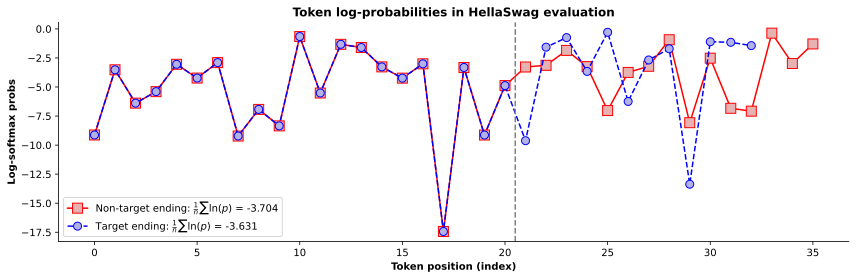

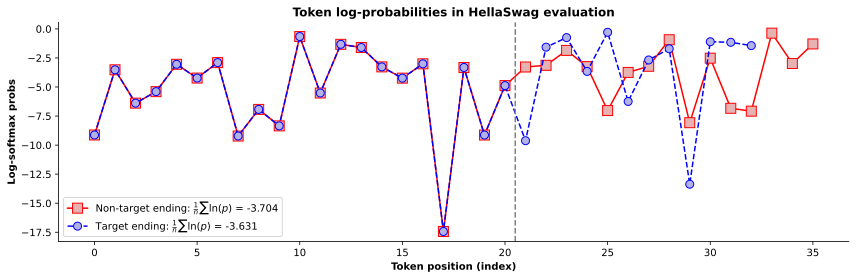

In [35]:
# visualize the logits
plt.figure(figsize=(12,4))
plt.plot(lsmSeqI,'s-',color='r',markersize=10,markerfacecolor=[.9,.7,.7],label=f'Non-target ending: $\\frac{{1}}{{n}}\\sum\\ln(p)$ = {probI:.3f}')
plt.plot(lsmSeqC,'o--',color='b',markersize=8 ,markerfacecolor=[.7,.7,.9],label=f'Target ending: $\\frac{{1}}{{n}}\\sum\\ln(p)$ = {probC:.3f}')
plt.axvline(context_len-1.5,linestyle='--',color='gray')

plt.gca().set(xlabel='Token position (index)',ylabel='Log-softmax probs',
              title='Token log-probabilities in HellaSwag evaluation')
plt.legend()

plt.tight_layout()
plt.savefig('ch4_proj22_part3.png')
plt.show()

# **Part 4: A function to test one HellaSwag sample**

In [36]:
# define a pad token for GPT2 (RoBERTa already has a pad token)
tokenizerG.pad_token_id = tokenizerG.eos_token_id
tokenizerG.pad_token_id

50256

50256

In [37]:
# demo of padding during tokenization
texts = [ 'hello',
          'my name is',
          'Mike and I like purple.'
]

t = tokenizerG(texts,padding=True,return_tensors='pt')
for k,v in t.items():
  print(f'"{k}":\n{v}\n')

"input_ids":
tensor([[31373, 50256, 50256, 50256, 50256, 50256],
        [ 1820,  1438,   318, 50256, 50256, 50256],
        [16073,   290,   314,   588, 14032,    13]])

"attention_mask":
tensor([[1, 0, 0, 0, 0, 0],
        [1, 1, 1, 0, 0, 0],
        [1, 1, 1, 1, 1, 1]])

"input_ids":
tensor([[31373, 50256, 50256, 50256, 50256, 50256],
        [ 1820,  1438,   318, 50256, 50256, 50256],
        [16073,   290,   314,   588, 14032,    13]])

"attention_mask":
tensor([[1, 0, 0, 0, 0, 0],
        [1, 1, 1, 0, 0, 0],
        [1, 1, 1, 1, 1, 1]])



In [38]:
# a function to calculate accuracy on one sample
def oneHellaSample(sample,model,tokenizer):

  # 1) find context length and target
  context = sample['ctx']
  context_len = len( tokenizer.encode(context) )
  target = int(sample['label']) # the target answer

  # 2) loop over candidate endings and create prompts
  allprompts = []
  for opti in range(len(sample['endings'])):
    prompt = f"{context} {sample['endings'][opti]}"
    allprompts.append(prompt)

  # 3) batch tokenize with padding token
  prompt_tox = tokenizer(allprompts,padding=True,return_tensors='pt')

  # 4) run all prompts in one batch and bring the logits back to the CPU
  output = model(**prompt_tox.to(device))
  logits = output.logits.cpu()

  # 5) convert to log probabilities
  log_probs = F.log_softmax(logits,dim=-1)

  # 6) initialize and populate the log-likelihood vector
  loglikelihoods = np.zeros(len(sample['endings']))

  # log-probs for each ending
  for opti in range(len(sample['endings'])):

    # get the token for this ending
    token_seq = prompt_tox['input_ids'][opti].cpu()

    # find the valid (non-pad) tokens
    valid_tox = np.where(token_seq.numpy() != tokenizer.pad_token_id)[0]

    # extract a log-softmax sequence for the valid tokens
    lsmSeq = np.array([ log_probs[opti,i,token_seq[i+1]].item() for i in valid_tox[:-1]])

    # average the valid ending log-probs
    loglikelihoods[opti] = np.mean(lsmSeq[context_len-1:])

  # 7) function outputs
  return loglikelihoods,target

In [39]:
# test it with one sample
loglikelihoods,target = oneHellaSample(dataset[42],gpt2_s,tokenizerG)

print(f'Log-likelihoods: {loglikelihoods}')
print(f'Target ending: {target}')

if np.argmax(loglikelihoods)==target:
  print('Model was correct!')
else:
  print('Model needs more training ;)')

Log-likelihoods: [-2.94458387 -5.43872503 -3.17445235 -2.28751862]
Target ending: 3
Model was correct!
Log-likelihoods: [-2.94458387 -5.43872503 -3.17445235 -2.28751862]
Target ending: 3
Model was correct!


# **Part 5: Test all four models**

In [40]:
# number of data samples to test (set low on CPU!)
num_samples = 1000

# initialize accuracy matrix
accuracies = np.zeros((4,num_samples))


# loop over data samples with progress bar
for datai in tqdm(range(num_samples),desc='Evaluating on HellaSwag'):

  # extract one sample from the data
  example = dataset[datai]

  # test GPT2 small
  loglikelihoods,target = oneHellaSample(example,gpt2_s,tokenizerG)
  if np.argmax(loglikelihoods)==target: accuracies[0,datai] = 1

  # repeat for GPT2-large
  loglikelihoods,target = oneHellaSample(example,gpt2_l,tokenizerG)
  if np.argmax(loglikelihoods)==target: accuracies[1,datai] = 1

  # repeat for roberta-small
  loglikelihoods,target = oneHellaSample(example,roberta_s,tokenizerR)
  if np.argmax(loglikelihoods)==target: accuracies[2,datai] = 1

  # repeat for roberta-large
  loglikelihoods,target = oneHellaSample(example,roberta_l,tokenizerR)
  if np.argmax(loglikelihoods)==target: accuracies[3,datai] = 1

Evaluating on HellaSwag: 100%|██████████| 1000/1000 [06:39<00:00,  2.50it/s]


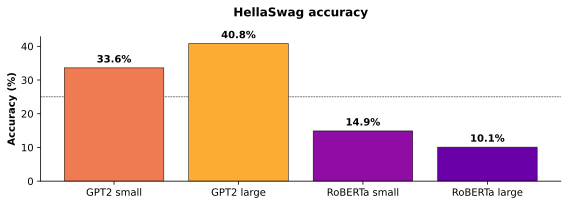

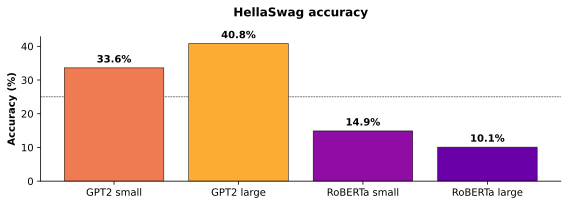

In [41]:
plt.figure(figsize=(8,3))

# draw each bar at a time (for color and text labels)
for i in range(4):

  # accuracy for this model
  acy = 100*accuracies[i,:].mean()

  # the bar
  plt.bar(i,acy,color=plt.cm.plasma(2*acy/100),edgecolor='k',linewidth=.5)

  # write the actual accuracy value
  plt.text(i,1+acy,f'{acy:.1f}%',
           fontweight='bold',ha='center',va='bottom')

# adjust the axies
plt.axhline(25,linestyle='--',color='k',linewidth=.5,zorder=-10)
plt.gca().set(xticks=range(4),xticklabels=['GPT2 small','GPT2 large','RoBERTa small','RoBERTa large'],
              ylabel='Accuracy (%)')
plt.title('HellaSwag accuracy',y=1.1)

plt.tight_layout()
plt.savefig('ch4_proj22_part5a.png')
plt.show()

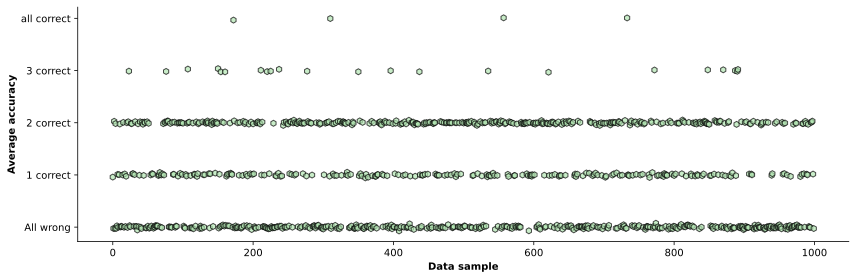

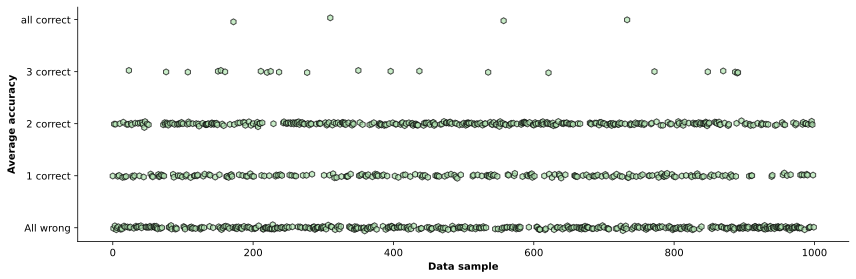

In [42]:
plt.figure(figsize=(12,4))
plt.plot(accuracies.mean(axis=0)+np.random.normal(0,.005,num_samples),'kh',markerfacecolor=[.7,.9,.7,.7])
plt.gca().set(xlabel='Data sample',ylabel='Average accuracy',yticks=np.linspace(0,1,5),
              yticklabels=['All wrong','1 correct','2 correct','3 correct','all correct'])

plt.tight_layout()
plt.savefig('ch4_proj22_part5b.png')
plt.show()

# **Part 6: Statistical comparisons**

In [43]:
# initialize the results matrix
statsMat = np.zeros((4,4,2))

# loop over all pairs
for i in range(4):
  for j in range(i+1,4):

    # extract this pair of accuracies
    a = accuracies[i]
    b = accuracies[j]

    # initialize and populate the McNemar table (diagonals are ignored in the test)
    table = np.zeros((2,2))
    table[0,1] = np.sum((a==0) & (b==1))
    table[1,0] = np.sum((a==1) & (b==0))

    # run the McNemar test
    res = mcnemar(table,exact=False,correction=True)

    # store the mean differences (% accuracy) and p-value
    statsMat[i,j,0] = 100*(a.mean() - b.mean())
    statsMat[i,j,1] = res.pvalue

statsMat[statsMat==0] = np.nan

In [44]:
# mean differences
statsMat[:,:,0]

array([[ nan, -7.2, 18.7, 23.5],
       [ nan,  nan, 25.9, 30.7],
       [ nan,  nan,  nan,  4.8],
       [ nan,  nan,  nan,  nan]])

array([[ nan, -7.2, 18.7, 23.5],
       [ nan,  nan, 25.9, 30.7],
       [ nan,  nan,  nan,  4.8],
       [ nan,  nan,  nan,  nan]])

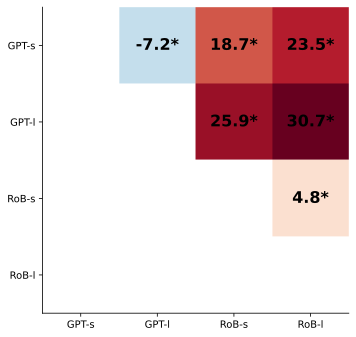

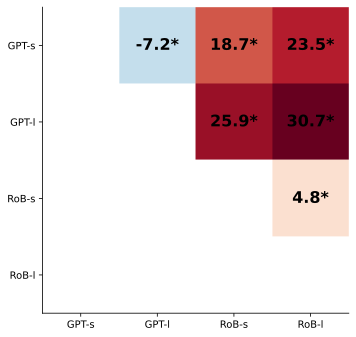

In [45]:
# show the matrix
plt.imshow(statsMat[:,:,0],cmap=plt.cm.RdBu_r,vmin=-30,vmax=30)
plt.gca().set(xticks=range(4),yticks=range(4),
              xticklabels=['GPT-s','GPT-l','RoB-s','RoB-l'],yticklabels=['GPT-s','GPT-l','RoB-s','RoB-l'])

# and add the labels
for i in range(4):
  for j in range(i+1,4):

    # create the base label
    label = f'{statsMat[i,j,0]:.1f}'

    # add * if its significant
    if statsMat[i,j,1]<.05/6:
      label += '*'

    # draw the text
    plt.text(j,i,label,fontsize=16,fontweight='bold',color='k',ha='center',va='center')

plt.tight_layout()
plt.savefig('ch4_proj22_part6.png')
plt.show()

In [46]:
# btw, there are some linguistic imperfections in the HellaSwag dataset, e.g.,
dataset[2]

{'ind': 106,
 'activity_label': 'Canoeing',
 'ctx_a': 'Two women in a child are shown in a canoe while a man pulls the canoe while standing in the water, with other individuals visible in the background.',
 'ctx_b': 'the child and a different man',
 'ctx': 'Two women in a child are shown in a canoe while a man pulls the canoe while standing in the water, with other individuals visible in the background. the child and a different man',
 'endings': ['are then shown paddling down a river in a boat while a woman talks.',
  'are driving the canoe, they go down the river flowing side to side.',
  'sit in a canoe while the man paddles.',
  'walking go down the rapids, while the man in his helicopter almost falls and goes out of canoehood.'],
 'source_id': 'activitynet~v_-xQvJmC2jhk',
 'split': 'val',
 'split_type': 'indomain',
 'label': '2'}

{'ind': 106,
 'activity_label': 'Canoeing',
 'ctx_a': 'Two women in a child are shown in a canoe while a man pulls the canoe while standing in the water, with other individuals visible in the background.',
 'ctx_b': 'the child and a different man',
 'ctx': 'Two women in a child are shown in a canoe while a man pulls the canoe while standing in the water, with other individuals visible in the background. the child and a different man',
 'endings': ['are then shown paddling down a river in a boat while a woman talks.',
  'are driving the canoe, they go down the river flowing side to side.',
  'sit in a canoe while the man paddles.',
  'walking go down the rapids, while the man in his helicopter almost falls and goes out of canoehood.'],
 'source_id': 'activitynet~v_-xQvJmC2jhk',
 'split': 'val',
 'split_type': 'indomain',
 'label': '2'}